# Bài 2 (Trang 18 - 19): Phân tích dữ liệu Mall Customers
**Họ tên:** Trần Minh Tấn - **MSSV:** 6451071071

## Câu 1) Nhập dữ liệu, thống kê các thông tin cơ bản, xử lý dữ liệu bị thiếu

In [1]:
import pandas as pd
import numpy as np

# Đọc dữ liệu trực tiếp từ Google Drive (không cần upload lên Colab)
file_id = "1bsPcz8nZOMPcF3eVVs-EfmDRsqfjjUcC"
url = f"https://drive.google.com/uc?export=download&id={file_id}"
data = pd.read_csv(url)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Đã đọc dữ liệu Mall_Customers từ Google Drive")
print("Kích thước dữ liệu (dòng, cột):", data.shape)
print("\n5 dòng đầu tiên:")
print(data.head())

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Đã đọc dữ liệu Mall_Customers từ Google Drive
Kích thước dữ liệu (dòng, cột): (200, 5)

5 dòng đầu tiên:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [2]:
print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Thông tin các cột:")
data.info()

print("\nThống kê mô tả các thuộc tính số:")
print(data.describe())

print("\nThống kê thuộc tính Gender:")
print(data["Gender"].value_counts())

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Thông tin các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Thống kê mô tả các thuộc tính số:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000

In [3]:
print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
# Kiểm tra dữ liệu bị thiếu
print("Số giá trị thiếu của từng cột:")
print(data.isnull().sum())
print("\nSố dòng bị trùng lặp:", data.duplicated().sum())

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Số giá trị thiếu của từng cột:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Số dòng bị trùng lặp: 0


In [4]:
print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
# Xử lý dữ liệu bị thiếu:
#  - Cột số: điền bằng giá trị trung vị (median)
#  - Cột chữ (Gender): điền bằng giá trị xuất hiện nhiều nhất (mode)
for col in data.columns:
    if data[col].isnull().sum() > 0:
        if data[col].dtype == "object":
            data[col] = data[col].fillna(data[col].mode()[0])
        else:
            data[col] = data[col].fillna(data[col].median())

print("Số giá trị thiếu sau khi xử lý:")
print(data.isnull().sum())

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Số giá trị thiếu sau khi xử lý:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


## Câu 2) Biểu đồ tần suất (Histogram) cho Tuổi, Thu nhập hằng năm và Số điểm mua sắm

Họ tên: Trần Minh Tấn - MSSV: 6451071071


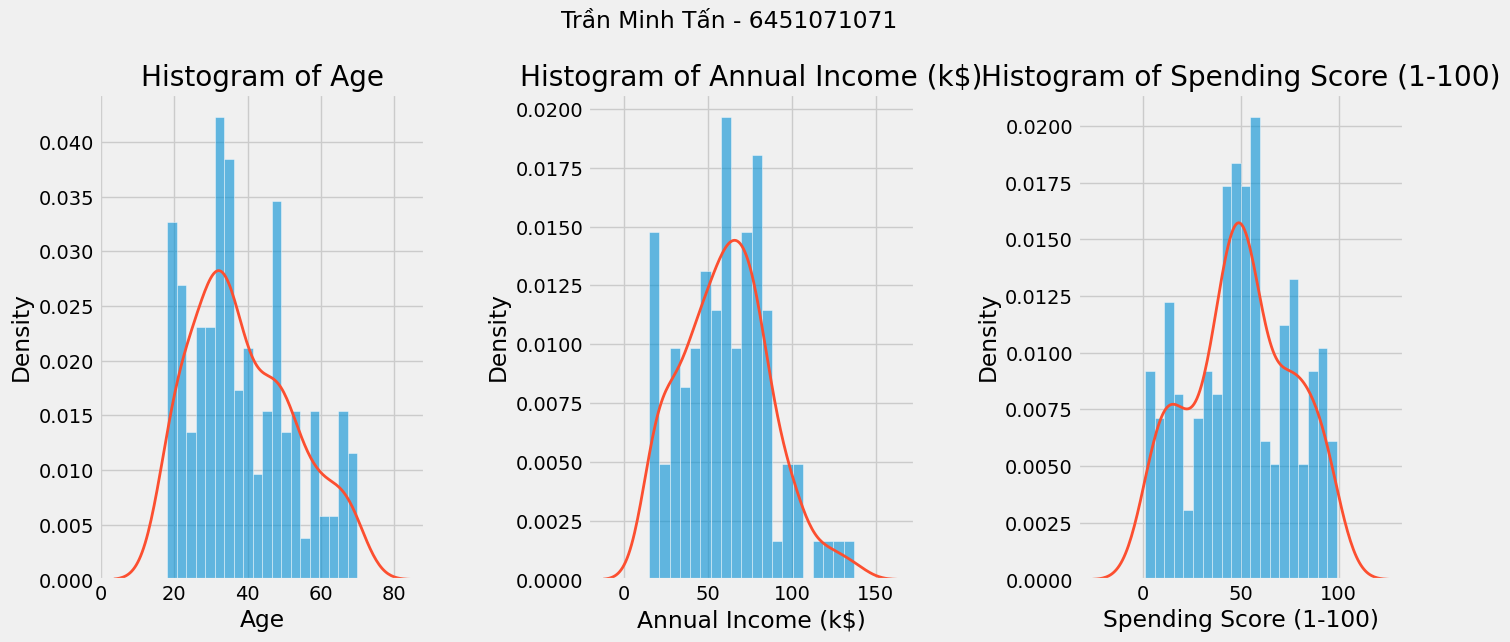

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")

plt.style.use('fivethirtyeight')
plt.figure(1, figsize=(15, 6))
n = 0
for x in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    plt.hist(data[x], bins=20, density=True, alpha=0.6, edgecolor='white')
    sns.kdeplot(data[x], linewidth=2)
    plt.title('Histogram of {}'.format(x))
    plt.xlabel(x)
plt.suptitle("Trần Minh Tấn - 6451071071", y=1.02)
plt.show()